# 03 · Enrichment: does added information create skill?

`02_real_assets` found that price history alone carries no exploitable signal at a 5-observation horizon: TimesFM ties the random walk, every decision model is worse, and prices showed neither reversal nor momentum. This notebook keeps the same instruments, period and decision points and asks whether *added* information changes that, and whether each kind of model can use it:

- **A. Related assets**: other instruments' prices, as covariates for TimesFM 3.0 and as extra history in the decision models' state.
- **B. Indicators**: common technical indicators written into the decision models' state. They are functions of the same prices, so they add no information; the question is whether they help decision models *read* the series.
- **C. News** and **D. Search interest**: external sources, added once their historical access has been checked.

Each variant is compared with the **price-only** forecasts of the same models on the same decision points, and with the random walk. Using decision models to turn text into features for TimesFM, ensembles and agreement filters are left to `04_combinations`, which needs each source's own results first.

Variants A and B come first with their results; C and D follow in their own section, with a different design because headlines can be recalled. Decision models: clef and lev throughout, plus kev-9b and laya in the indicator variant (see [Variants](#Variants)).

## Setup

In [16]:
import os
import re
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from sbench import plots, tsfm
from sbench.backtest import decision_points, load_results, run_forecast_backtest
from sbench.context import NewsFeed, SearchInterest, covariates
from sbench.data import (
    BINANCE_DAILY_CLOSE,
    ECB_REFERENCE_FIX,
    GOOGLE_TRENDS_DAY,
    US_MARKET_CLOSE,
    Series,
    cached,
    load_ecb_rate,
    load_google_trends,
    truncate,
)
from sbench.elicitation import BinDistribution, DirectionChoice, ThresholdNoul
from sbench.forecast import make_task
from sbench.predictors import DecisionModelPredictor, EmpiricalPredictor, RandomWalkPredictor
from sbench.scoring import per_forecast, skill_table, summary
from sbench.states import build_indicator_state, build_news_state, build_price_state, build_search_state
from sbench.tsfm import QuantilePredictor, TimesFM3

os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")
os.environ.setdefault("HF_HUB_OFFLINE", "1")   # weights are cached; never re-check the Hub
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PRICES_02 = ROOT / "data" / "snapshots" / "02_real_assets"   # same price snapshots as 02
SNAPSHOTS = ROOT / "data" / "snapshots" / "03_enrichment"    # new snapshots (ECB rates); committed
RESULTS = ROOT / "data" / "results" / "03_enrichment"        # one CSV per variant; committed
CHARTS = ROOT / "outputs" / "03_enrichment"                  # regenerated; not committed

HISTORY_START, SCORE_START, CHECK_START, END = "2023-01-01", "2024-01-01", "2026-03-01", "2026-09-30"
HORIZON = 5            # forecast 5 observations ahead
STEP = 5               # non-overlapping horizons
MIN_HISTORY = 100      # observations before the first decision point
STATE_LOOKBACK = 60    # rows of the instrument's own history shown to decision models
RELATED_LOOKBACK = 20  # rows of each related series shown to decision models (variant A)

plots.use_style()
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

## The panel

The eight instruments of 02, with one change: **FX now comes from the ECB's euro reference rates** instead of Yahoo. Yahoo's daily FX close has no consistent time (its daily EUR/USD and USD/JPY closes match hourly prices from mid-afternoon UTC the day before to early morning on the labelled day), so it cannot be aligned with news or with other markets. The ECB fixes its rates at 14:15 Frankfurt time on every TARGET business day; USD/JPY is the cross of the euro rates on the same fixing. Reference rates are not tradable quotes, but they track the market closely.

Every series now records **when its close becomes known**, not just its date label:

| Instruments | Source | Close known at |
|---|---|---|
| BTC, ETH | Binance | 00:00 UTC the day after the label |
| SPY, AAPL, GLD, USO | Yahoo | 16:00 New York |
| EURUSD, USDJPY | ECB reference rates | 14:15 Frankfurt |

In [2]:
PANEL = [
    # key, class, source, symbol, description shown to the models, unit, close time
    ("BTC", "crypto", "02", "BTC", "Bitcoin (BTC) priced in USDT on Binance: daily close price", "USDT", BINANCE_DAILY_CLOSE),
    ("ETH", "crypto", "02", "ETH", "Ether (ETH) priced in USDT on Binance: daily close price", "USDT", BINANCE_DAILY_CLOSE),
    ("SPY", "equity", "02", "SPY", "SPDR S&P 500 ETF Trust (SPY): daily close price", "USD", US_MARKET_CLOSE),
    ("AAPL", "equity", "02", "AAPL", "Apple Inc. (AAPL) shares: daily close price", "USD", US_MARKET_CLOSE),
    ("GLD", "commodity", "02", "GLD", "SPDR Gold Shares ETF (GLD): daily close price", "USD", US_MARKET_CLOSE),
    ("USO", "commodity", "02", "USO", "United States Oil Fund ETF (USO): daily close price", "USD", US_MARKET_CLOSE),
    ("EURUSD", "fx", "ecb", ("EUR", "USD"), "Euro / US dollar ECB reference rate (EUR/USD): daily fixing", "USD",
     ECB_REFERENCE_FIX),
    ("USDJPY", "fx", "ecb", ("USD", "JPY"), "US dollar / Japanese yen from ECB reference rates (USD/JPY): daily fixing",
     "JPY", ECB_REFERENCE_FIX),
]
ASSET_CLASS = {key: cls for key, cls, *_ in PANEL}


def load_prices(source: str, symbol) -> pd.DataFrame:
    if source == "02":
        return cached(PRICES_02 / f"{symbol}.csv", None)   # frozen in 02; never re-downloaded
    return cached(SNAPSHOTS / f"{symbol[0]}{symbol[1]}_ECB.csv", load_ecb_rate, *symbol, start=HISTORY_START, end=END)


SERIES = [Series(key, description, truncate(load_prices(source, symbol), HISTORY_START, END), unit=unit,
                 close_time=close, meta={"asset_class": cls})
          for key, cls, source, symbol, description, unit, close in PANEL]
BY_KEY = {s.key: s for s in SERIES}

pd.DataFrame([{
    "series": s.key, "class": s.meta["asset_class"], "rows": len(s), "first": s.df["t"].min().date(),
    "last": s.df["t"].max().date(), "first close known (UTC)": pd.Timestamp(s.available_at()[0]),
} for s in SERIES]).set_index("series")

,class,rows,first,last,first close known (UTC)
series,,,,,
BTC,crypto,1369,2023-01-01,2026-09-30,2023-01-02 00:00:00
ETH,crypto,1369,2023-01-01,2026-09-30,2023-01-02 00:00:00
SPY,equity,939,2023-01-03,2026-09-30,2023-01-03 21:00:00
AAPL,equity,939,2023-01-03,2026-09-30,2023-01-03 21:00:00
GLD,commodity,939,2023-01-03,2026-09-30,2023-01-03 21:00:00
USO,commodity,939,2023-01-03,2026-09-30,2023-01-03 21:00:00
EURUSD,fx,957,2023-01-02,2026-09-30,2023-01-02 13:15:00
USDJPY,fx,957,2023-01-02,2026-09-30,2023-01-02 13:15:00


## Using only what was known

With several sources, a date label is not enough: a Binance candle labelled with a given date closes at midnight UTC, three to four hours *after* the US close on the same date. Matching by label would let a forecast for SPY see Bitcoin's close from later that evening. Every input is therefore taken as known at the decision series' close (`ForecastTask.known_at`, `sbench.data.known_rows`): in the task, in the decision models' state and in TimesFM's covariates. The example below is a SPY decision point with BTC as a related series: BTC's bar with the same date label is not yet available, so the latest BTC value used is the previous day's.

In [3]:
spy, btc = BY_KEY["SPY"], BY_KEY["BTC"]
i = decision_points(spy, HORIZON, MIN_HISTORY, STEP, start=SCORE_START)[0]
task = make_task(spy, i, HORIZON, related=(btc,))
used = len(task.related_history(btc)) - 1
pd.DataFrame({
    "label": [task.t.date(), btc.df["t"].iloc[used].date(), btc.df["t"].iloc[used + 1].date()],
    "known at (UTC)": [task.known_at, pd.Timestamp(btc.available_at()[used]), pd.Timestamp(btc.available_at()[used + 1])],
}, index=["SPY close (decision)", "BTC bar used", "next BTC bar (not yet known)"])

,label,known at (UTC)
SPY close (decision),2024-01-02,2024-01-02 21:00:00
BTC bar used,2024-01-01,2024-01-02 00:00:00
next BTC bar (not yet known),2024-01-02,2024-01-03 00:00:00


## Variants

| Variant | TimesFM 3.0 | Decision models |
|---|---|---|
| **price** (reference) | own history | named state: the last 60 closes |
| **A. related** | own history plus two related series as past-only covariates | named state plus the last 20 known closes of each related series |
| **B. indicators** | not applicable (indicators are functions of the context it already has) | named state plus moving averages, Bollinger bands, RSI and the 20-observation change |

Related series per instrument, fixed before any results (other choices can be tested later):

| Instrument | Related | Why |
|---|---|---|
| BTC | ETH, SPY | crypto co-movement; general risk appetite |
| ETH | BTC, SPY | same |
| SPY | AAPL, USDJPY | largest constituent; the yen as a risk-off gauge |
| AAPL | SPY, USDJPY | market factor; same |
| GLD | EURUSD, USDJPY | gold is priced in dollars; safe-haven flows |
| USO | SPY, EURUSD | growth demand; the dollar |
| EURUSD | USDJPY, GLD | the dollar's other main cross; the gold–dollar link |
| USDJPY | EURUSD, SPY | same; risk sentiment |

**Decision models.** clef (`threshold_noul`) and lev (`direction_choice`), the two carried from 02, run every variant. Two weaker readers run the price and indicator variants only, each in its best format from 01: kev-9b (`threshold_noul`), which leaned against the trend and bearish in 01 and 02, and laya (`bin_score`), a small encoder that could hardly read the price series at all. Indicators summarise the series in words, so if they help anyone it should be these two; related series would only lengthen a state they already read poorly.

Decision models get the **named** state throughout: 02 found that names and dates help them, and that recall of the test period does not explain the gain. The price-only forecasts are re-run here rather than reused from 02, so every comparison uses the same FX source and the same conditions.

The same decision point in each state (the history rows are abbreviated):

In [4]:
RELATED = {
    "BTC": ("ETH", "SPY"), "ETH": ("BTC", "SPY"), "SPY": ("AAPL", "USDJPY"), "AAPL": ("SPY", "USDJPY"),
    "GLD": ("EURUSD", "USDJPY"), "USO": ("SPY", "EURUSD"), "EURUSD": ("USDJPY", "GLD"), "USDJPY": ("EURUSD", "SPY"),
}
STATES = {
    "price": partial(build_price_state, lookback=STATE_LOOKBACK),
    "related": partial(build_price_state, lookback=STATE_LOOKBACK, related_lookback=RELATED_LOOKBACK),
    "indicators": partial(build_indicator_state, lookback=STATE_LOOKBACK),
}


def related_for(s: Series, variant: str) -> tuple:
    return tuple(BY_KEY[k] for k in RELATED[s.key]) if variant == "related" else ()


def preview(state: str, keep: int = 3) -> str:
    out, run = [], 0
    for line in state.splitlines():
        is_row = re.match(r"\s+\d{4}-\d{2}-\d{2}: ", line) is not None   # dated history rows
        run = run + 1 if is_row else 0
        if not is_row or run <= keep:
            out.append(line)
        elif run == keep + 1:
            out.append("  ...")
    return "\n".join(out)


example_series = BY_KEY["GLD"]
example_idx = decision_points(example_series, HORIZON, MIN_HISTORY, STEP, start=SCORE_START)[-1]
for variant, state in STATES.items():
    t = make_task(example_series, example_idx, HORIZON, related=related_for(example_series, variant))
    print(f"===== {variant}\n{preview(state(t))}\n")

===== price
SPDR Gold Shares ETF (GLD): daily close price
Decision time: 2026-09-18
Current close price: 401.17 USD
History (oldest → newest):
  2026-06-25: 369.46 USD
  2026-06-26: 373.63 USD
  2026-06-29: 368.58 USD
  ...

===== related
SPDR Gold Shares ETF (GLD): daily close price
Decision time: 2026-09-18
Current close price: 401.17 USD
History (oldest → newest):
  2026-06-25: 369.46 USD
  2026-06-26: 373.63 USD
  2026-06-29: 368.58 USD
  ...

Related: Euro / US dollar ECB reference rate (EUR/USD): daily fixing
  2026-08-24: 1.1664 USD
  2026-08-25: 1.1662 USD
  2026-08-26: 1.1669 USD
  ...

Related: US dollar / Japanese yen from ECB reference rates (USD/JPY): daily fixing
  2026-08-24: 159.12 JPY
  2026-08-25: 159.24 JPY
  2026-08-26: 159.07 JPY
  ...

===== indicators
SPDR Gold Shares ETF (GLD): daily close price
Decision time: 2026-09-18
Current close price: 401.17 USD
History (oldest → newest):
  2026-06-25: 369.46 USD
  2026-06-26: 373.63 USD
  2026-06-29: 368.58 USD
  ...

In

## Decision points

As in 02: every 5 observations from January 2024, at least 100 observations of history, every outcome observed. FX now follows the ECB's fixing calendar, so its decision points differ slightly from 02's.

In [5]:
IDXS = {s.key: decision_points(s, HORIZON, min_history=MIN_HISTORY, step=STEP, start=SCORE_START) for s in SERIES}
points = pd.DataFrame([{
    "series": s.key, "class": s.meta["asset_class"], "points": len(IDXS[s.key]),
    "first": s.df["t"].iloc[IDXS[s.key][0]].date(), "last": s.df["t"].iloc[IDXS[s.key][-1]].date(),
} for s in SERIES]).set_index("series")
display(points)
print(f"{points['points'].sum()} decision points in total")

,class,points,first,last
series,,,,
BTC,crypto,200,2024-01-01,2026-09-22
ETH,crypto,200,2024-01-01,2026-09-22
SPY,equity,137,2024-01-02,2026-09-18
AAPL,equity,137,2024-01-02,2026-09-18
GLD,commodity,137,2024-01-02,2026-09-18
USO,commodity,137,2024-01-02,2026-09-18
EURUSD,fx,140,2024-01-02,2026-09-22
USDJPY,fx,140,2024-01-02,2026-09-22


1228 decision points in total


## Predictors

In [6]:
DECISION_MODELS = {   # model: (format, variants it runs)
    "clef": (ThresholdNoul(), ("price", "related", "indicators")),
    "lev": (DirectionChoice(include_flat=False), ("price", "related", "indicators")),
    "kev-9b": (ThresholdNoul(), ("price", "indicators")),
    "laya": (BinDistribution("score"), ("price", "indicators")),
}

REFERENCE = {   # predictors that need no model server, per variant
    "price": [RandomWalkPredictor(), EmpiricalPredictor(), QuantilePredictor(TimesFM3(), name="timesfm3", log_space=True)],
    "related": [QuantilePredictor(TimesFM3(), name="timesfm3+related", log_space=True, use_related=True)],
    "indicators": [],
}


def available(model: str) -> bool:
    # One full-size request (the longest state, nine questions) before committing hours to a model.
    t = make_task(example_series, example_idx, HORIZON, related=related_for(example_series, "related"))
    try:
        DecisionModelPredictor(model, ThresholdNoul(), STATES["related"]).predict(t)
        return True
    except Exception as e:  # noqa: BLE001 -- reported, model skipped
        print(f"{model}: unavailable, skipped ({str(e).splitlines()[0][:160]})")
        return False


SERVED = [m for m in DECISION_MODELS if available(m)]
DECISION = {   # decision-model predictors per variant; names carry the variant
    variant: [DecisionModelPredictor(m, fmt, state, name=f"{m}/{fmt.name}" + ("" if variant == "price" else f"+{variant}"))
              for m in SERVED for fmt, variants in [DECISION_MODELS[m]] if variant in variants]
    for variant, state in STATES.items()
}
print(f"{len(SERVED)}/{len(DECISION_MODELS)} decision models available: {', '.join(SERVED)}")
for variant in STATES:
    print(f"{variant:10s}: " + ", ".join(p.name for p in REFERENCE[variant] + DECISION[variant]))

4/4 decision models available: clef, lev, kev-9b, laya
price     : random_walk, empirical, timesfm3, clef/threshold_noul, lev/direction_choice, kev-9b/threshold_noul, laya/bin_score
related   : timesfm3+related, clef/threshold_noul+related, lev/direction_choice+related
indicators: clef/threshold_noul+indicators, lev/direction_choice+indicators, kev-9b/threshold_noul+indicators, laya/bin_score+indicators


## Running the backtest

One results file per variant (a file's configuration includes the related series, which differ by variant), each resumable as in 02. TimesFM and the baselines run first and then release the GPU; each decision model then runs all three variants while it is loaded. At warm latencies (about 4 s per decision point for clef's nine questions, 2 s for kev-9b, under 1 s for lev and laya; longer with the related-series state) the run takes roughly 7 hours.

In [7]:
def run(variant: str, predictors: list) -> None:
    for s in SERIES:
        run_forecast_backtest(s, predictors, HORIZON, RESULTS / f"{variant}.csv", IDXS[s.key],
                              related=related_for(s, variant), verbose=False)


for variant, preds in REFERENCE.items():
    if preds:
        run(variant, preds)
tsfm.release()   # TimesFM would otherwise hold GPU memory the model server needs
for m in SERVED:
    for variant, preds in DECISION.items():
        run(variant, [p for p in preds if p.model == m])

results = pd.concat([load_results(RESULTS / f"{v}.csv").assign(variant=v) for v in STATES], ignore_index=True)
results = results[results["series"].isin(IDXS) & (results["horizon"] == HORIZON)].reset_index(drop=True)
expected = pd.Series({k: len(v) for k, v in IDXS.items()})
coverage = results.groupby(["predictor", "series"])["t"].nunique().unstack().reindex(columns=expected.index)
missing = coverage.fillna(0).lt(expected, axis=1)
print(f"{results['predictor'].nunique()} predictors; predictor/series pairs with missing decision points: "
      f"{int(missing.to_numpy().sum())}")

14 predictors; predictor/series pairs with missing decision points: 0


## Results

Scores are computed per forecast as in 02 (`lo`, `hi`: 95% paired bootstrap interval of the skill). Each variant is set against two references on the same decision points: the random walk, which is the bar for skill, and the **same model's price-only forecasts**, which is the comparison the variants were designed for. Results for variants C and D will be added below in the same form.

In [8]:
REFS = {"random_walk", "empirical"}
METRICS = {"crps_n": "CRPS", "brier_up": "Brier on P(up)"}


def skill_cols(df: pd.DataFrame, metric: str, label: str) -> pd.DataFrame:
    sk = skill_table(df, metric).set_index("predictor")
    return sk[["N", "skill", "lo", "hi"]].rename(columns=lambda c: c if c == "N" else f"{label}_{c}")


per = per_forecast(results)
per["base"] = per["predictor"].str.replace(r"\+\w+$", "", regex=True)   # the same model on price only
per["variant"] = per["predictor"].str.extract(r"\+(\w+)$", expand=False).fillna("price")
per["asset_class"] = per["series"].map(ASSET_CLASS)

full = per[per["crps_n"].notna()]
direction_only = per.loc[per["crps_n"].isna(), "predictor"].unique()
pooled = summary(per, by=("horizon",), ci=False).loc[HORIZON]
brier_up = skill_cols(per, "brier_up", "brier_up")
up_rate = per.loc[per["predictor"] == "random_walk", "up"].mean()

display(Markdown(f"Realised up-rate over all {per['predictor'].eq('random_walk').sum()} decision points: "
                 f"**{up_rate:.1%}**"))
display(Markdown("**Full distributions** (threshold and bin formats, TimesFM, baselines)"))
display(skill_cols(full, "crps_n", "crps")
        .join(brier_up.drop(columns="N"))
        .join(pooled[["cover_80", "coherence", "p_spread"]])
        .sort_values("crps_skill", ascending=False))
display(Markdown("**Direction only** (P(up) formats)"))
display(brier_up.loc[direction_only].sort_values("brier_up_skill", ascending=False))

Realised up-rate over all 1228 decision points: **56.1%**

**Full distributions** (threshold and bin formats, TimesFM, baselines)

,N,crps_skill,crps_lo,crps_hi,brier_up_skill,brier_up_lo,brier_up_hi,cover_80,coherence,p_spread
predictor,,,,,,,,,,
timesfm3+related,1228,-0.007,-0.020,0.005,-0.010,-0.029,0.010,0.787,0.000,0.969
timesfm3,1228,-0.010,-0.024,0.003,-0.016,-0.037,0.004,0.796,0.000,0.968
empirical,1228,-0.018,-0.034,-0.003,-0.026,-0.053,0.001,0.780,0.000,0.933
clef/threshold_noul+indicators,1228,-0.024,-0.037,-0.013,-0.030,-0.050,-0.012,0.823,0.021,0.874
clef/threshold_noul,1228,-0.033,-0.047,-0.021,-0.037,-0.057,-0.017,0.821,0.023,0.878
kev-9b/threshold_noul+indicators,1228,-0.041,-0.054,-0.029,-0.042,-0.063,-0.022,0.836,0.019,0.818
clef/threshold_noul+related,1228,-0.042,-0.057,-0.026,-0.039,-0.059,-0.019,0.849,0.032,0.865
kev-9b/threshold_noul,1228,-0.069,-0.085,-0.053,-0.101,-0.128,-0.073,0.876,0.023,0.764
laya/bin_score,1228,-0.088,-0.106,-0.072,-0.022,-0.034,-0.009,0.921,0.000,0.827


**Direction only** (P(up) formats)

,N,brier_up_skill,brier_up_lo,brier_up_hi
predictor,,,,
lev/direction_choice+related,1228,-0.021,-0.041,-0.001
lev/direction_choice+indicators,1228,-0.032,-0.059,-0.004
lev/direction_choice,1228,-0.035,-0.062,-0.009


### Against the random walk

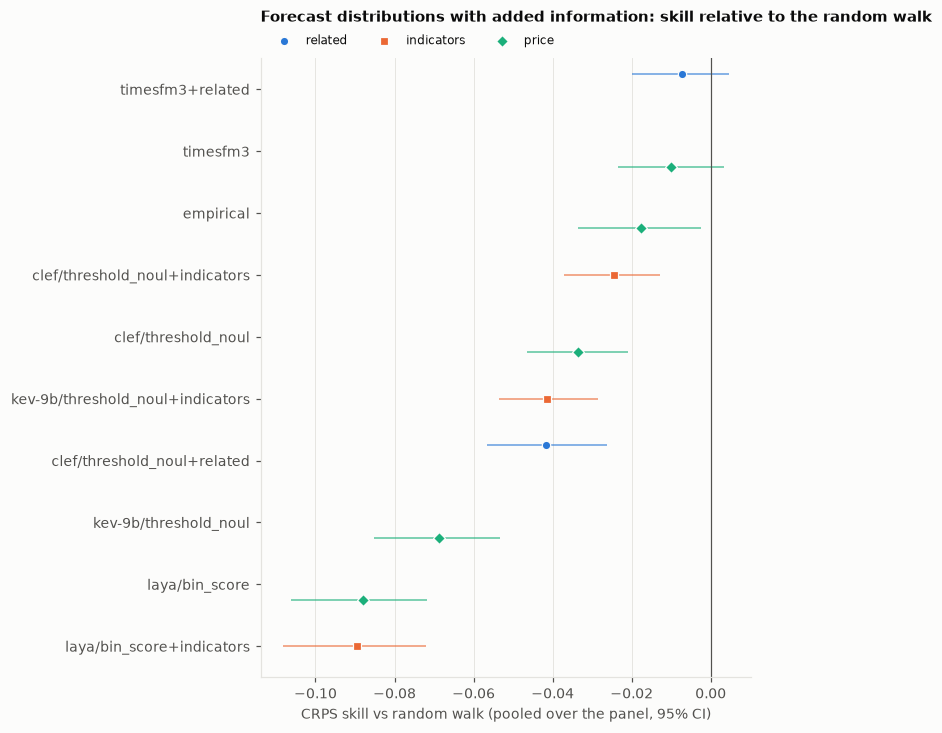

In [9]:
HUE_ORDER = ["related", "indicators", "price"]   # same colour per variant in every chart
sk = skill_table(full, "crps_n").merge(per[["predictor", "variant"]].drop_duplicates(), on="predictor")
plots.dot_plot(sk.sort_values("variant", key=lambda v: v.map(HUE_ORDER.index)), y="predictor", x="skill",
               hue="variant", lo="lo", hi="hi", order=sk.sort_values("skill", ascending=False)["predictor"],
               xlabel="CRPS skill vs random walk (pooled over the panel, 95% CI)",
               title="Forecast distributions with added information: skill relative to the random walk",
               path=CHARTS / "01_crps_skill.png");

### Each variant against the same model on price only

The skill of each variant *relative to the same model's price-only forecasts* (1 − score with the variant / score on price only, paired on decision points). Positive means the added information improved that model's forecasts, whether or not it brought them up to the random walk.

,,skill,lo,hi,N
model,variant,,,,
timesfm3 (CRPS),related,0.003,-0.006,0.011,1228
timesfm3 (Brier on P(up)),related,0.006,-0.007,0.020,1228
clef/threshold_noul (CRPS),related,-0.008,-0.017,0.001,1228
clef/threshold_noul (Brier on P(up)),related,-0.002,-0.016,0.011,1228
lev/direction_choice (Brier on P(up)),related,0.014,-0.002,0.029,1228
clef/threshold_noul (CRPS),indicators,0.009,-0.001,0.019,1228
clef/threshold_noul (Brier on P(up)),indicators,0.007,-0.009,0.022,1228
lev/direction_choice (Brier on P(up)),indicators,0.003,-0.017,0.023,1228
kev-9b/threshold_noul (CRPS),indicators,0.026,0.016,0.036,1228


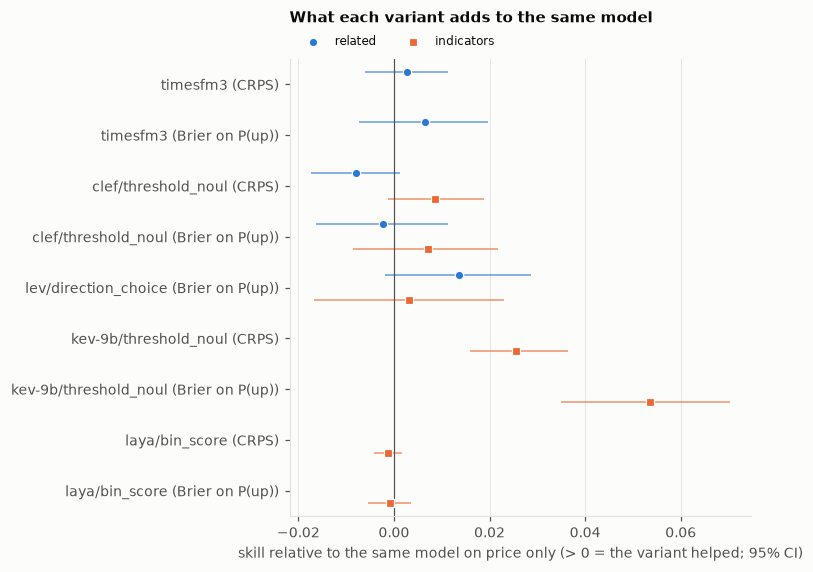

In [10]:
rows = []
for name in per.loc[per["variant"] != "price", "predictor"].unique():
    base, variant = name.split("+")
    for metric, label in METRICS.items():
        d = per[per["predictor"].isin([name, base])].dropna(subset=[metric])
        if d["predictor"].nunique() < 2:
            continue   # direction-only formats have no CRPS
        s = skill_table(d, metric, baseline=base).iloc[0]
        rows.append({"model": f"{base} ({label})", "variant": variant, "skill": s["skill"],
                     "lo": s["lo"], "hi": s["hi"], "N": s["N"]})
gain = pd.DataFrame(rows)
plots.dot_plot(gain, y="model", x="skill", hue="variant", lo="lo", hi="hi",
               xlabel="skill relative to the same model on price only (> 0 = the variant helped; 95% CI)",
               title="What each variant adds to the same model", path=CHARTS / "02_variant_vs_price.png")
gain.set_index(["model", "variant"])

### By asset class

Skill against the random walk on each class's decision points (two instruments each; blue = better than the random walk, red = worse).

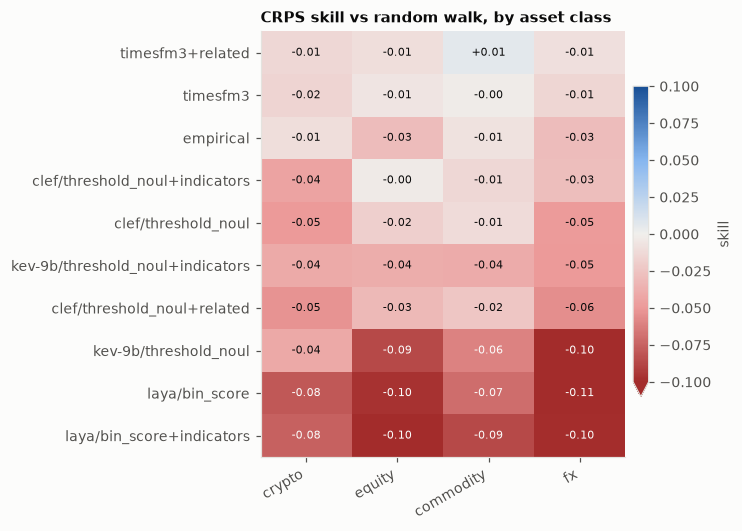

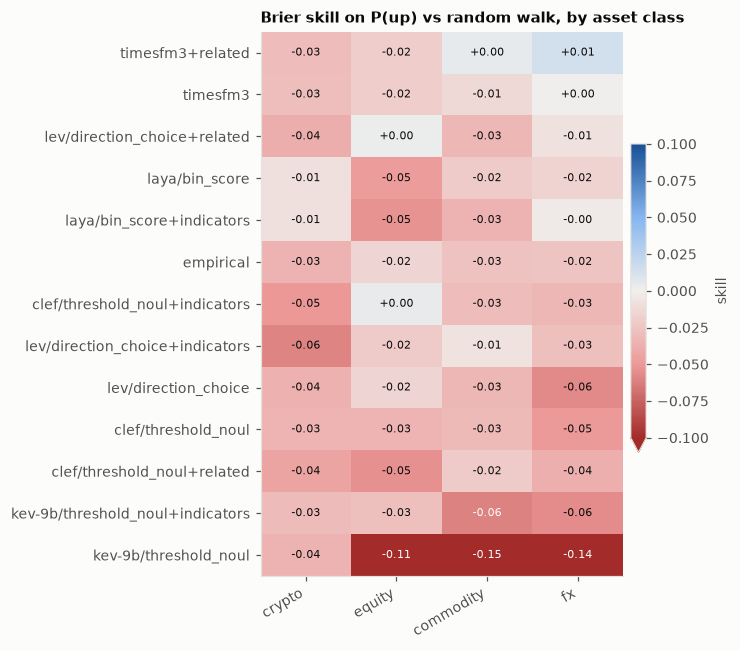

In [11]:
CLASSES = ["crypto", "equity", "commodity", "fx"]


def by_class(df: pd.DataFrame, metric: str) -> pd.DataFrame:
    t = skill_table(df, metric, by=("asset_class",)).pivot(index="predictor", columns="asset_class", values="skill")
    return t[CLASSES].loc[skill_table(df, metric).sort_values("skill", ascending=False)["predictor"]]


plots.heatmap(by_class(full, "crps_n"), span=0.1, title="CRPS skill vs random walk, by asset class",
              cbar_label="skill", path=CHARTS / "03_crps_by_class.png")
plots.heatmap(by_class(per, "brier_up"), span=0.1, title="Brier skill on P(up) vs random walk, by asset class",
              cbar_label="skill", path=CHARTS / "04_brier_by_class.png");

### What the indicators changed in the answers

How each model's P(up) relates to two things the indicator state spells out: Bollinger %B (0 = price on the lower band, 1 = on the upper band) and the move over the previous 20 observations (in units of recent volatility, as in 02). A negative slope means the model expects reversals, a positive one that it expects the move to continue. The realised slopes show what prices actually did at the same decision points.

The Bollinger reversal noted after 02 was found on this same 2024–2026 window, so the realised slope here is not an independent test of it; that test is left to the forward test on new data.

In [12]:
TRAIL = 20
feats = []
for s in SERIES:
    c = s.df["close"]
    mid, sd = c.rolling(20).mean(), c.rolling(20).std()   # as in the indicator state
    lr = np.log(c)
    feats.append(pd.DataFrame({"series": s.key, "t": s.df["t"], "pct_b": (c - (mid - 2 * sd)) / (4 * sd),
                               "trail_z": (lr - lr.shift(TRAIL)) / (lr.diff().rolling(30).std() * np.sqrt(TRAIL))}))
x = per.merge(pd.concat(feats), on=["series", "t"])

points_x = x[x["predictor"] == "random_walk"]
realised = {c: np.polyfit(points_x[c], points_x["up"].astype(float), 1)[0] for c in ("pct_b", "trail_z")}
display(Markdown(f"Realised up-rate slope: {realised['pct_b']:+.3f} per unit of %B, "
                 f"{realised['trail_z']:+.3f} per unit of previous move"))

with_indicators = list(per.loc[per["variant"] == "indicators", "base"].unique())
rows = []
for (base, variant), g in (x[x["base"].isin(with_indicators) & x["variant"].isin(["price", "indicators"])]
                           .dropna(subset=["p_up"]).groupby(["base", "variant"])):
    rows.append({"model": base, "variant": variant, "mean P(up)": g["p_up"].mean(), "sd P(up)": g["p_up"].std(),
                 "slope on %B": np.polyfit(g["pct_b"], g["p_up"], 1)[0],
                 "slope on previous move": np.polyfit(g["trail_z"], g["p_up"], 1)[0]})
pd.DataFrame(rows).set_index(["model", "variant"]).reindex(
    pd.MultiIndex.from_product([with_indicators, ["price", "indicators"]], names=["model", "variant"]))

Realised up-rate slope: -0.064 per unit of %B, -0.002 per unit of previous move

mean P(up)  sd P(up)  slope on %B  slope on previous move
model                 variant                                                              
clef/threshold_noul   price            0.497     0.085       -0.071                  -0.012
                      indicators       0.475     0.081       -0.053                  -0.006
lev/direction_choice  price            0.535     0.112        0.068                   0.033
                      indicators       0.568     0.103        0.130                   0.063
kev-9b/threshold_noul price            0.420     0.090       -0.135                  -0.023
                      indicators       0.466     0.085       -0.077                   0.001
laya/bin_score        price            0.464     0.039       -0.038                  -0.012
                      indicators       0.467     0.043       -0.049                  -0.014

### Interim conclusions: variants A and B

**Neither related assets nor indicators produce skill against the random walk.** TimesFM with related series is the best predictor (CRPS skill −0.007, interval −0.020 to +0.005) and TimesFM on price only is next (−0.010, −0.024 to +0.003); both are statistically tied with the random walk and well calibrated, as in 02. Every decision-model forecast in every variant remains worse than the random walk. Prices rose at 56.1% of decision points.

**1. Related assets (A) add nothing measurable at this horizon.** Against its own price-only forecasts, TimesFM with related covariates gains +0.003 in CRPS (−0.006 to +0.011) and +0.006 in Brier on P(up) (−0.007 to +0.020). For clef the longer state is slightly worse (CRPS −0.008, −0.017 to +0.001); lev's direction answers improve slightly (+0.014, −0.002 to +0.029), an interval that only just reaches zero. Daily closes of other assets, taken as known at the decision time, carry little that the asset's own history does not.

**2. Indicators (B) help the weakest reader, as expected, but do not create skill.** kev-9b gains the most of any model in any variant: +0.026 in CRPS (+0.016 to +0.036) and +0.054 in Brier on P(up) (+0.035 to +0.070), moving its CRPS skill from −0.069 to −0.041, close to clef on price only. The change is in its leanings rather than any new signal: its bearish tilt shrinks (mean P(up) 0.42 to 0.47) and its fading of high %B roughly halves (slope −0.135 to −0.077). clef improves slightly (CRPS +0.009, −0.001 to +0.019), mostly on equities. laya is unaffected (CRPS −0.001, −0.004 to +0.002): its answers hardly move with the state (standard deviation of P(up) about 0.04), so it does not read either version closely enough for the difference to matter. lev's direction answers do not improve (+0.003, −0.017 to +0.023), and with indicators it follows the move more strongly (slope on %B +0.068 to +0.130), against what prices did at these decision points.

**3. Precomputed indicators make decision models less biased, not better informed.** This matches the expectation set before the run: indicators are functions of the prices, so they can correct how a model reads the series but cannot add information the series lacks. They are worth keeping in the state for weaker models; the Bollinger reversal remains a hypothesis for the forward test.

Variants C (news) and D (search interest) bring information that is not in the prices; they follow below.

## Variants C and D: news and search interest

News and search interest are the first inputs here that are not functions of prices. They also bring a risk that prices did not: **recall**. A headline such as "Bitcoin rebounds to $70K as Middle East tension eases" names the asset, the date and the event, and cannot be blinded the way prices were in 02. A model that saw coverage of the following days during training could answer from memory. The design follows from that:

- **Main window: from March 2026**, after the release of Qwen3.5 (February 2026), the base of lev. Its base model's pretraining cannot cover this period. clef's base and cutoff are not published, so its results here remain an upper bound.
- **Horizon 1, every trading day** in that window (about 1,350 decision points): news moves prices quickly, and one-day steps give enough points to separate effects in seven months. New price-only forecasts at horizon 1 are run for the pairing.
- **Horizon 5 on the decision points of A and B**, over the whole 2024–2026 window, comparable with A and B but exposed to recall before March 2026. If C looks better before March 2026 than after it, the gap points to recall rather than reading.
- **Models:** clef and lev, as in variant A. kev-9b and laya only gained from summarised input, and lists of headlines are the opposite.

**C. News.** Built from GDELT's Global Knowledge Graph: one 15-minute file per hour (a quarter of all English-language coverage GDELT records), collected by `sbench.news` into `data/raw/gkg/` (not committed; re-downloadable). An article counts for an instrument when its title names it; ticker-tagged feed headlines (holdings changes, short interest) are dropped. Each article is taken as known 15 minutes after its file's time stamp. Decision models see the price state plus a coverage line (headline count, share of all news against the previous 30 days, average tone), up to 15 headlines about the instrument from the last 24 hours, newest first, and up to 5 macro and policy headlines (tariffs, central banks, inflation, coverage of posts on Truth Social, for which no complete archive of the posts themselves exists). TimesFM gets the coverage share and tone as covariates. GDELT's archive has a gap from 14 June to 2 July 2025; decision points whose last 24 hours fall in it have no news and are left out of C's comparisons.

**D. Search interest.** Daily worldwide Google Trends per instrument, stitched from 90-day windows (`sbench.data.load_google_trends`). Each Trends request is scaled by its own peak, which can lie after the day being read; only ratios between days are used, which carry no such information: the last 7 days against the previous 28, and the latest day against the last 7. A day's value is taken as known at the end of the following day. Decision models see one line with both ratios, and TimesFM gets their logarithms as covariates.

The search term per instrument was chosen before any of this window was used: candidates were compared on June–November 2023 by the rank correlation of daily search interest with the size of that day's price move, and the top one kept.

| Instrument | Candidates (rank correlation with the day's absolute return) | Chosen |
|---|---|---|
| BTC | bitcoin 0.37 · bitcoin, finance category 0.41 · btc 0.42 | btc |
| ETH | ethereum 0.30 · ethereum, finance 0.35 · eth 0.44 | eth |
| SPY | stock market 0.18 · s&p 500 0.26 · stock market, finance 0.11 | s&p 500 |
| AAPL | apple stock 0.07 · aapl 0.14 · apple, finance 0.09 | aapl |
| GLD | gold price 0.11 · gold, finance 0.06 · gold 0.03 | gold price |
| USO | oil price 0.13 · crude oil 0.19 · oil, finance 0.12 | crude oil |
| EURUSD | euro dollar 0.04 · eur usd 0.14 · euro, finance 0.04 | eur usd |
| USDJPY | yen 0.20 · usd jpy 0.24 · yen, finance 0.28 | yen, finance |

With 124–180 days per comparison, differences below about 0.1 are within noise; the correlations say search interest follows the *size* of moves, not their direction.

In [13]:
NEWS_START, TRENDS_START = "2023-12-01", "2023-11-01"   # 30 days of baseline before the first decision point
IDXS_H1 = {s.key: decision_points(s, 1, min_history=MIN_HISTORY, step=1, start=CHECK_START) for s in SERIES}
print(f"horizon 1 from {CHECK_START}: {sum(map(len, IDXS_H1.values()))} decision points; "
      f"horizon 5: {sum(map(len, IDXS.values()))}")

NEWS_LABELS = {"BTC": "Bitcoin", "ETH": "Ether", "SPY": "US stocks", "AAPL": "Apple", "GLD": "gold",
               "USO": "oil", "EURUSD": "the euro", "USDJPY": "the yen"}
NEWS_DIR = SNAPSHOTS / "news"
if not (NEWS_DIR / "news_coverage.csv.gz").exists():
    # Built once from the raw GKG store; only the headlines shown at the decision points are kept.
    full_feed = NewsFeed.from_raw(ROOT / "data" / "raw" / "gkg", NEWS_START, END)
    asked = [(s.key, pd.Timestamp(s.available_at()[i])) for s in SERIES for i in {*IDXS[s.key], *IDXS_H1[s.key]}]
    full_feed.restrict_to(asked).save(NEWS_DIR)
FEED = NewsFeed.load(NEWS_DIR, labels=NEWS_LABELS)

TRENDS_TERMS = {"BTC": ("btc", 0), "ETH": ("eth", 0), "SPY": ("s&p 500", 0), "AAPL": ("aapl", 0),
                "GLD": ("gold price", 0), "USO": ("crude oil", 0), "EURUSD": ("eur usd", 0), "USDJPY": ("yen", 7)}
SEARCH = SearchInterest(
    {k: Series(k, f"Google searches for '{term}'",
               cached(SNAPSHOTS / f"trends_{k}.csv", load_google_trends, term, TRENDS_START, END, cat=cat, pause=30),
               kind="covariate", close_time=GOOGLE_TRENDS_DAY)
     for k, (term, cat) in TRENDS_TERMS.items()},
    {k: term + (" (finance category)" if cat else "") for k, (term, cat) in TRENDS_TERMS.items()})

pd.DataFrame([{
    "series": s.key,
    "news, h=1": pd.Series([FEED.coverage_at(s.key, s.available_at()[i]) is not None for i in IDXS_H1[s.key]]).mean(),
    "news, h=5": pd.Series([FEED.coverage_at(s.key, s.available_at()[i]) is not None for i in IDXS[s.key]]).mean(),
    "median headlines per day": FEED.coverage[f"n_{s.key}"].groupby(FEED.coverage["hour"].dt.date).sum().median(),
    "search, h=5": pd.Series([SEARCH.ratios(s.key, s.available_at()[i]) is not None for i in IDXS[s.key]]).mean(),
} for s in SERIES]).set_index("series").rename(columns=lambda c: c if c.startswith("median") else f"{c} available")

horizon 1 from 2026-03-01: 1312 decision points; horizon 5: 1228


,"news, h=1 available","news, h=5 available",median headlines per day,"search, h=5 available"
series,,,,
BTC,1.000,0.980,32.000,1.000
ETH,1.000,0.980,8.000,1.000
SPY,1.000,0.978,185.000,1.000
AAPL,1.000,0.978,82.000,1.000
GLD,1.000,0.978,97.000,1.000
USO,1.000,0.978,105.000,1.000
EURUSD,1.000,0.979,16.000,1.000
USDJPY,1.000,0.979,6.000,1.000


The first run downloads Google Trends (about 150 requests, spaced 30 s apart and slowed further when Google throttles: one to two hours) and builds the news snapshot from the raw store (about a minute); both are then read from `data/snapshots/03_enrichment/`.

The same decision point in the news and search states (USO on 10 March 2026, during the oil spike; price history abbreviated):

In [14]:
COVARIATES = {   # TimesFM covariates per instrument, computed at each of its closes
    "news": {s.key: covariates(s, partial(FEED.features, s.key), prefix="news_") for s in SERIES},
    "search": {s.key: covariates(s, partial(SEARCH.features, s.key)) for s in SERIES},
}
STATES_CD = {
    "price": STATES["price"],
    "news": partial(build_news_state, feed=FEED, lookback=STATE_LOOKBACK),
    "search": partial(build_search_state, interest=SEARCH, lookback=STATE_LOOKBACK),
}

uso = BY_KEY["USO"]
i = int(uso.df.index[uso.df["t"] == "2026-03-10"][0])
for variant in ("news", "search"):
    print(f"===== {variant}\n{preview(STATES_CD[variant](make_task(uso, i, 1, related=COVARIATES[variant]['USO'])))}\n")

===== news
United States Oil Fund ETF (USO): daily close price
Decision time: 2026-03-10
Current close price: 105.86 USD
History (oldest → newest):
  2025-12-11: 69.25 USD
  2025-12-12: 68.81 USD
  2025-12-15: 67.89 USD
  ...

News from English-language sources (GDELT), last 24 hours:
  Coverage: 778 articles with oil in the headline, 3.2× the usual share of all news (previous 30 days); average tone -3.2 (previous 30 days -2.9; below 0 = negative)
  Headlines about oil (newest first):
    2026-03-10 19:00 UTC  hometownregister.com  Oil plunges, stocks rise as Trump says Iran war over 'very soon'
    2026-03-10 19:00 UTC  dominicantoday.com  Asian stock markets slide after oil prices spike on Middle East conflict
    2026-03-10 19:00 UTC  cbsnews.com  Oil prices are falling — gas prices aren't. Here's why.
    2026-03-10 19:00 UTC  weeklyblitz.net  Russia's shadow fleet militarized: Wagner veterans and GRU operatives guard sanctioned oil tankers
    2026-03-10 19:00 UTC  cp24.com  Iran 

### Running C and D

Results go to one file per variant and horizon (`price_h1`, `news_h1`, `search_h1`, `news`, `search`); the horizon-5 price-only forecasts are those of variant A and B's `price` file. As before, TimesFM and the baselines run first and release the GPU, then each decision model runs all files while loaded. At warm latencies this takes roughly 10 hours, mostly clef at horizon 1; the run resumes where it stopped.

In [15]:
CD_MODELS = {"clef": ThresholdNoul(), "lev": DirectionChoice(include_flat=False)}
RUNS = {   # results file: (horizon, decision points, variant)
    "price_h1": (1, IDXS_H1, "price"),
    "news_h1": (1, IDXS_H1, "news"),
    "search_h1": (1, IDXS_H1, "search"),
    "news": (HORIZON, IDXS, "news"),
    "search": (HORIZON, IDXS, "search"),
}


def cd_references(variant: str) -> list:
    if variant == "price":
        return [RandomWalkPredictor(), EmpiricalPredictor(), QuantilePredictor(TimesFM3(), name="timesfm3", log_space=True)]
    return [QuantilePredictor(TimesFM3(), name=f"timesfm3+{variant}", log_space=True, use_related=True)]


def cd_decision(variant: str, model: str) -> list:
    fmt = CD_MODELS[model]
    return [DecisionModelPredictor(model, fmt, STATES_CD[variant],
                                   name=f"{model}/{fmt.name}" + ("" if variant == "price" else f"+{variant}"))]


def run_cd(file: str, predictors: list) -> None:
    horizon, idxs, variant = RUNS[file]
    for s in SERIES:
        run_forecast_backtest(s, predictors, horizon, RESULTS / f"{file}.csv", idxs[s.key],
                              related=COVARIATES.get(variant, {}).get(s.key, ()), verbose=False)


for file, (_, _, variant) in RUNS.items():
    run_cd(file, cd_references(variant))
tsfm.release()
for m in CD_MODELS:
    if m in SERVED:
        for file, (_, _, variant) in RUNS.items():
            run_cd(file, cd_decision(variant, m))

results_cd = pd.concat([load_results(RESULTS / f"{f}.csv").assign(file=f) for f in RUNS], ignore_index=True)
for file, (horizon, idxs, _) in RUNS.items():
    r = results_cd[(results_cd["file"] == file) & (results_cd["horizon"] == horizon)]
    expected = pd.Series({k: len(v) for k, v in idxs.items()})
    got = r.groupby(["predictor", "series"])["t"].nunique().unstack().reindex(columns=expected.index)
    print(f"{file:10s}: {r['predictor'].nunique()} predictors; pairs with missing decision points: "
          f"{int(got.fillna(0).lt(expected, axis=1).to_numpy().sum())}")

price_h1  : 5 predictors; pairs with missing decision points: 0
news_h1   : 3 predictors; pairs with missing decision points: 0
search_h1 : 3 predictors; pairs with missing decision points: 0
news      : 3 predictors; pairs with missing decision points: 0
search    : 3 predictors; pairs with missing decision points: 0


### Results: variants C and D

The main comparison is at horizon 1 from March 2026; horizon 5 covers the whole window and is split at March 2026 as a recall check. Decision points whose last 24 hours fall in GDELT's archive gap are left out of every comparison in this section, so all predictors are scored on the same points.

In [17]:
price_h5 = results[results["variant"] == "price"].drop(columns="variant")
per_cd = per_forecast(pd.concat([price_h5, results_cd.drop(columns="file")], ignore_index=True))
per_cd["base"] = per_cd["predictor"].str.replace(r"\+\w+$", "", regex=True)
per_cd["variant"] = per_cd["predictor"].str.extract(r"\+(\w+)$", expand=False).fillna("price")
per_cd["asset_class"] = per_cd["series"].map(ASSET_CLASS)

KNOWN_AT = {s.key: dict(zip(s.df["t"], s.available_at())) for s in SERIES}
points_cd = per_cd[["series", "t"]].drop_duplicates()
points_cd["news_ok"] = [FEED.coverage_at(k, KNOWN_AT[k][t]) is not None for k, t in zip(points_cd["series"], points_cd["t"])]
per_cd = per_cd.merge(points_cd, on=["series", "t"])
print(f"decision points without news (archive gap), left out: {int((~points_cd['news_ok']).sum())}")
per_cd = per_cd[per_cd["news_ok"]]
h1, h5 = per_cd[per_cd["horizon"] == 1], per_cd[per_cd["horizon"] == HORIZON]


def gains_vs_price(df: pd.DataFrame) -> pd.DataFrame:
    rows = []
    for name in df.loc[df["variant"] != "price", "predictor"].unique():
        base, variant = name.split("+")
        for metric, label in METRICS.items():
            d = df[df["predictor"].isin([name, base])].dropna(subset=[metric])
            if d["predictor"].nunique() < 2:
                continue
            s = skill_table(d, metric, baseline=base).iloc[0]
            rows.append({"model": f"{base} ({label})", "variant": variant, "skill": s["skill"],
                         "lo": s["lo"], "hi": s["hi"], "N": s["N"]})
    return pd.DataFrame(rows)


h1_brier = skill_cols(h1, "brier_up", "brier_up")
display(Markdown(f"Horizon 1, March to September 2026: realised up-rate "
                 f"**{h1.loc[h1['predictor'] == 'random_walk', 'up'].mean():.1%}**"))
display(skill_cols(h1[h1["crps_n"].notna()], "crps_n", "crps").join(h1_brier.drop(columns="N"), how="outer")
        .sort_values("brier_up_skill", ascending=False))

decision points without news (archive gap), left out: 26


Horizon 1, March to September 2026: realised up-rate **52.3%**

,N,crps_skill,crps_lo,crps_hi,brier_up_skill,brier_up_lo,brier_up_hi
predictor,,,,,,,
empirical,1312.000,-0.002,-0.011,0.007,-0.010,-0.025,0.005
timesfm3+news,1312.000,-0.003,-0.013,0.006,-0.012,-0.025,0.000
timesfm3,1312.000,-0.005,-0.015,0.004,-0.016,-0.030,-0.002
timesfm3+search,1312.000,-0.002,-0.012,0.008,-0.018,-0.032,-0.003
clef/threshold_noul+search,1312.000,-0.040,-0.052,-0.028,-0.026,-0.041,-0.011
lev/direction_choice,NaN,NaN,NaN,NaN,-0.030,-0.046,-0.014
clef/threshold_noul,1312.000,-0.041,-0.053,-0.029,-0.038,-0.056,-0.020
clef/threshold_noul+news,1312.000,-0.067,-0.085,-0.051,-0.061,-0.087,-0.037
lev/direction_choice+search,NaN,NaN,NaN,NaN,-0.068,-0.095,-0.041


#### Against the same model on price only, horizon 1

,,skill,lo,hi,N
model,variant,,,,
timesfm3 (CRPS),news,0.002,-0.005,0.009,1312
timesfm3 (Brier on P(up)),news,0.004,-0.007,0.014,1312
clef/threshold_noul (CRPS),news,-0.025,-0.036,-0.015,1312
clef/threshold_noul (Brier on P(up)),news,-0.022,-0.039,-0.005,1312
lev/direction_choice (Brier on P(up)),news,-0.132,-0.165,-0.099,1312
timesfm3 (CRPS),search,0.003,-0.005,0.011,1312
timesfm3 (Brier on P(up)),search,-0.002,-0.013,0.010,1312
clef/threshold_noul (CRPS),search,0.001,-0.005,0.006,1312
clef/threshold_noul (Brier on P(up)),search,0.012,0.002,0.022,1312


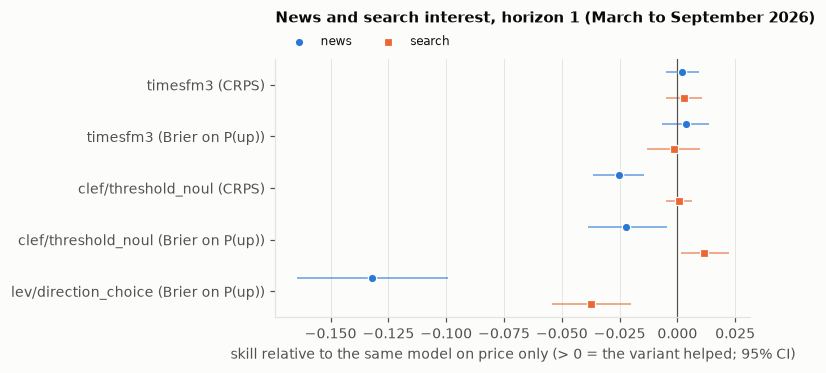

In [18]:
gain_h1 = gains_vs_price(h1)
plots.dot_plot(gain_h1, y="model", x="skill", hue="variant", lo="lo", hi="hi",
               xlabel="skill relative to the same model on price only (> 0 = the variant helped; 95% CI)",
               title="News and search interest, horizon 1 (March to September 2026)",
               path=CHARTS / "05_news_search_h1.png")
gain_h1.set_index(["model", "variant"])

#### Recall check, horizon 5

The same comparison at horizon 5, before and from March 2026. If recall of the test period drove the news results, news should help more before March 2026, when the period may be in the models' pretraining, than after it.

period                                         before March 2026  from March 2026
model                                 variant                                    
clef/threshold_noul (Brier on P(up))  news                 0.015            0.034
                                      search               0.018            0.028
clef/threshold_noul (CRPS)            news                 0.002            0.004
                                      search               0.004            0.006
lev/direction_choice (Brier on P(up)) news                -0.065           -0.025
                                      search              -0.016            0.002
timesfm3 (Brier on P(up))             news                 0.005           -0.020
                                      search               0.006           -0.004
timesfm3 (CRPS)                       news                 0.002           -0.014
                                      search               0.002           -0.008

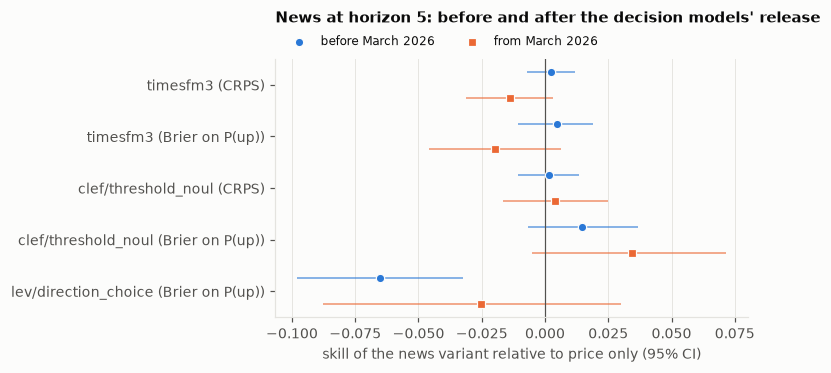

In [19]:
periods = {"before March 2026": h5[h5["t"] < CHECK_START], "from March 2026": h5[h5["t"] >= CHECK_START]}
gain_h5 = pd.concat([gains_vs_price(d).assign(period=p) for p, d in periods.items()], ignore_index=True)
plots.dot_plot(gain_h5[gain_h5["variant"] == "news"], y="model", x="skill", hue="period", lo="lo", hi="hi",
               xlabel="skill of the news variant relative to price only (95% CI)",
               title="News at horizon 5: before and after the decision models' release",
               path=CHARTS / "06_news_recall_check.png")
gain_h5.pivot_table(index=["model", "variant"], columns="period", values="skill")[list(periods)]

#### How news changes the answers

For each predictor at horizon 1: how spread out its P(up) is, how it moves with the last day's return (in units of recent volatility) and with the tone of the instrument's headlines (standardised per instrument), and how often its more likely direction was right. The realised slopes show what prices did next.

In [20]:
feats_cd = []
for s in SERIES:
    lr = np.log(s.df["close"])
    last = (lr.diff() / lr.diff().rolling(30).std()).set_axis(s.df["t"])
    pts = points_cd.loc[(points_cd["series"] == s.key) & points_cd["news_ok"], "t"]
    feats_cd.append(pd.DataFrame({"series": s.key, "t": pts.to_numpy(), "last_move": last.loc[pts].to_numpy(),
                                  "tone": [FEED.features(s.key, KNOWN_AT[s.key][t])["tone"] for t in pts]}))
feats_cd = pd.concat(feats_cd)
feats_cd["tone"] = feats_cd.groupby("series")["tone"].transform(lambda v: ((v - v.mean()) / v.std()).fillna(0))
x1 = h1.merge(feats_cd, on=["series", "t"]).dropna(subset=["p_up"])

pts1 = x1[x1["predictor"] == "random_walk"]
display(Markdown(f"Realised next-day up-rate slope: {np.polyfit(pts1['last_move'], pts1['up'].astype(float), 1)[0]:+.3f} "
                 f"per unit of last move, {np.polyfit(pts1['tone'], pts1['up'].astype(float), 1)[0]:+.3f} per unit of tone"))
pd.DataFrame([{
    "predictor": p, "mean P(up)": g["p_up"].mean(), "sd P(up)": g["p_up"].std(),
    "slope on last move": np.polyfit(g["last_move"], g["p_up"], 1)[0], "slope on tone": np.polyfit(g["tone"], g["p_up"], 1)[0],
    "hit rate": ((g["p_up"] > 0.5) == g["up"]).mean(),
} for p, g in x1[x1["predictor"] != "random_walk"].groupby("predictor")]).set_index("predictor")

Realised next-day up-rate slope: -0.013 per unit of last move, -0.014 per unit of tone

,mean P(up),sd P(up),slope on last move,slope on tone,hit rate
predictor,,,,,
clef/threshold_noul,0.462,0.072,0.008,0.000,0.486
clef/threshold_noul+news,0.452,0.097,0.039,0.014,0.480
clef/threshold_noul+search,0.485,0.067,0.013,0.002,0.491
empirical,0.521,0.062,0.002,-0.000,0.505
lev/direction_choice,0.472,0.069,0.032,-0.000,0.475
lev/direction_choice+news,0.420,0.168,0.069,0.032,0.482
lev/direction_choice+search,0.465,0.119,0.061,-0.003,0.489
timesfm3,0.499,0.064,0.015,-0.001,0.500
timesfm3+news,0.498,0.060,0.001,-0.002,0.505


#### Interim conclusions: variants C and D

**News makes the decision models more confident without making them more right.** At horizon 1 from March 2026, lev with news loses 0.132 in Brier skill against its own price-only answers (interval −0.165 to −0.099) and clef loses 0.025 in CRPS (−0.036 to −0.015). Both answers spread out (standard deviation of P(up): lev 0.069 to 0.168, clef 0.072 to 0.097) and lean with the last move and the tone of the headlines, while their hit rates stay below 50% (lev 47.5% to 48.2%, clef 48.6% to 48.0%). Prices did not follow: neither the last day's move nor the headlines' tone predicts the next day's direction (slopes −0.013 and −0.014). Headlines describe moves that are already in the price at the decision time; read as signals, they add confidence but no information. At horizon 5 the harm to lev is smaller (−0.057, −0.085 to −0.029) and clef's direction answers are slightly better (+0.019, −0.001 to +0.038).

**No sign of recall.** If the models answered from memory of the test period, news would help more before March 2026 than after it. It does not: for clef the Brier gain from news is +0.015 before (−0.007 to +0.037) and +0.034 after (−0.005 to +0.072), for lev −0.065 before and −0.025 after. The post-release sample is small (254 points), so this rules out a large recall effect, not a small one.

**Search interest corrects clef a little, like the indicators did for kev-9b.** clef's direction answers improve with search interest at both horizons: +0.012 at horizon 1 (+0.002 to +0.022) and +0.020 at horizon 5 (+0.008 to +0.031), before and after March 2026 alike. Its mean P(up) moves towards the realised base rate (0.462 to 0.485 at horizon 1), which is a correction of its bearish lean rather than new information; clef remains worse than the random walk. lev does worse with search interest (−0.038 at horizon 1).

**TimesFM is unaffected by either source.** With news covariates: +0.002 in CRPS at horizon 1 (−0.005 to +0.009); with search covariates: +0.003 (−0.005 to +0.011). Like the related-asset covariates of variant A, they neither help nor hurt.

## Conclusions

**1. None of the four kinds of added information produces skill against the random walk at these horizons.** Related assets, technical indicators, news and search interest were each tested against price-only forecasts of the same models on the same decision points. TimesFM 3.0 stays statistically tied with the random walk in every variant, and its covariates change nothing measurable. Every decision-model forecast in every variant remains worse than the random walk.

**2. Decision models gain from summaries and lose from raw text.** Precomputed indicators made kev-9b's forecasts clearly better (CRPS +0.026, Brier on P(up) +0.054 against its price-only answers), and search-interest ratios made clef's direction answers slightly better; in both cases the gain came from a smaller bearish lean, not from reading new information. Headlines did the opposite: they made lev and clef more confident in the direction of the news, and worse.

**3. Recall does not explain the results.** News helped no more on the period the models may have seen in pretraining than after their release, and on prices the named state's advantage in 02 did not shrink after release either.

**4. What this leaves for the next stages.** As forecasters fed with context, the decision models do not compete with a time-series model on liquid assets at one- and five-day horizons. Their remaining candidate roles are the ones 04 tests: turning text into features for TimesFM (classifying headlines rather than forecasting from them), and combining or gating forecasts. The forward test on new data will check the Bollinger reversal noted in 02 and repeat the news variant on a period no model can have seen.